          SquareFootage  NumBathrooms  NumBedrooms  RenovationQualityRate  \
count       7000.000000   7000.000000  7000.000000            7000.000000   
mean        1048.947459      2.117857     3.008571               5.016857   
std          426.010482      1.006889     1.021940               1.974766   
min          550.000000      1.000000     1.000000               1.000000   
25%          660.815000      1.000000     2.000000               4.000000   
50%          996.320000      2.000000     3.000000               5.000000   
75%         1342.292500      3.000000     4.000000               6.000000   
max         2874.700000      6.000000     7.000000              10.000000   
range       2324.700000      5.000000     6.000000               9.000000   
variance  181484.930511      1.013826     1.044361               3.899702   

          LocalAmenities  TransportAccess  SchoolRating  DistanceToCityCenter  
count        7000.000000      7000.000000   7000.000000           7000.0

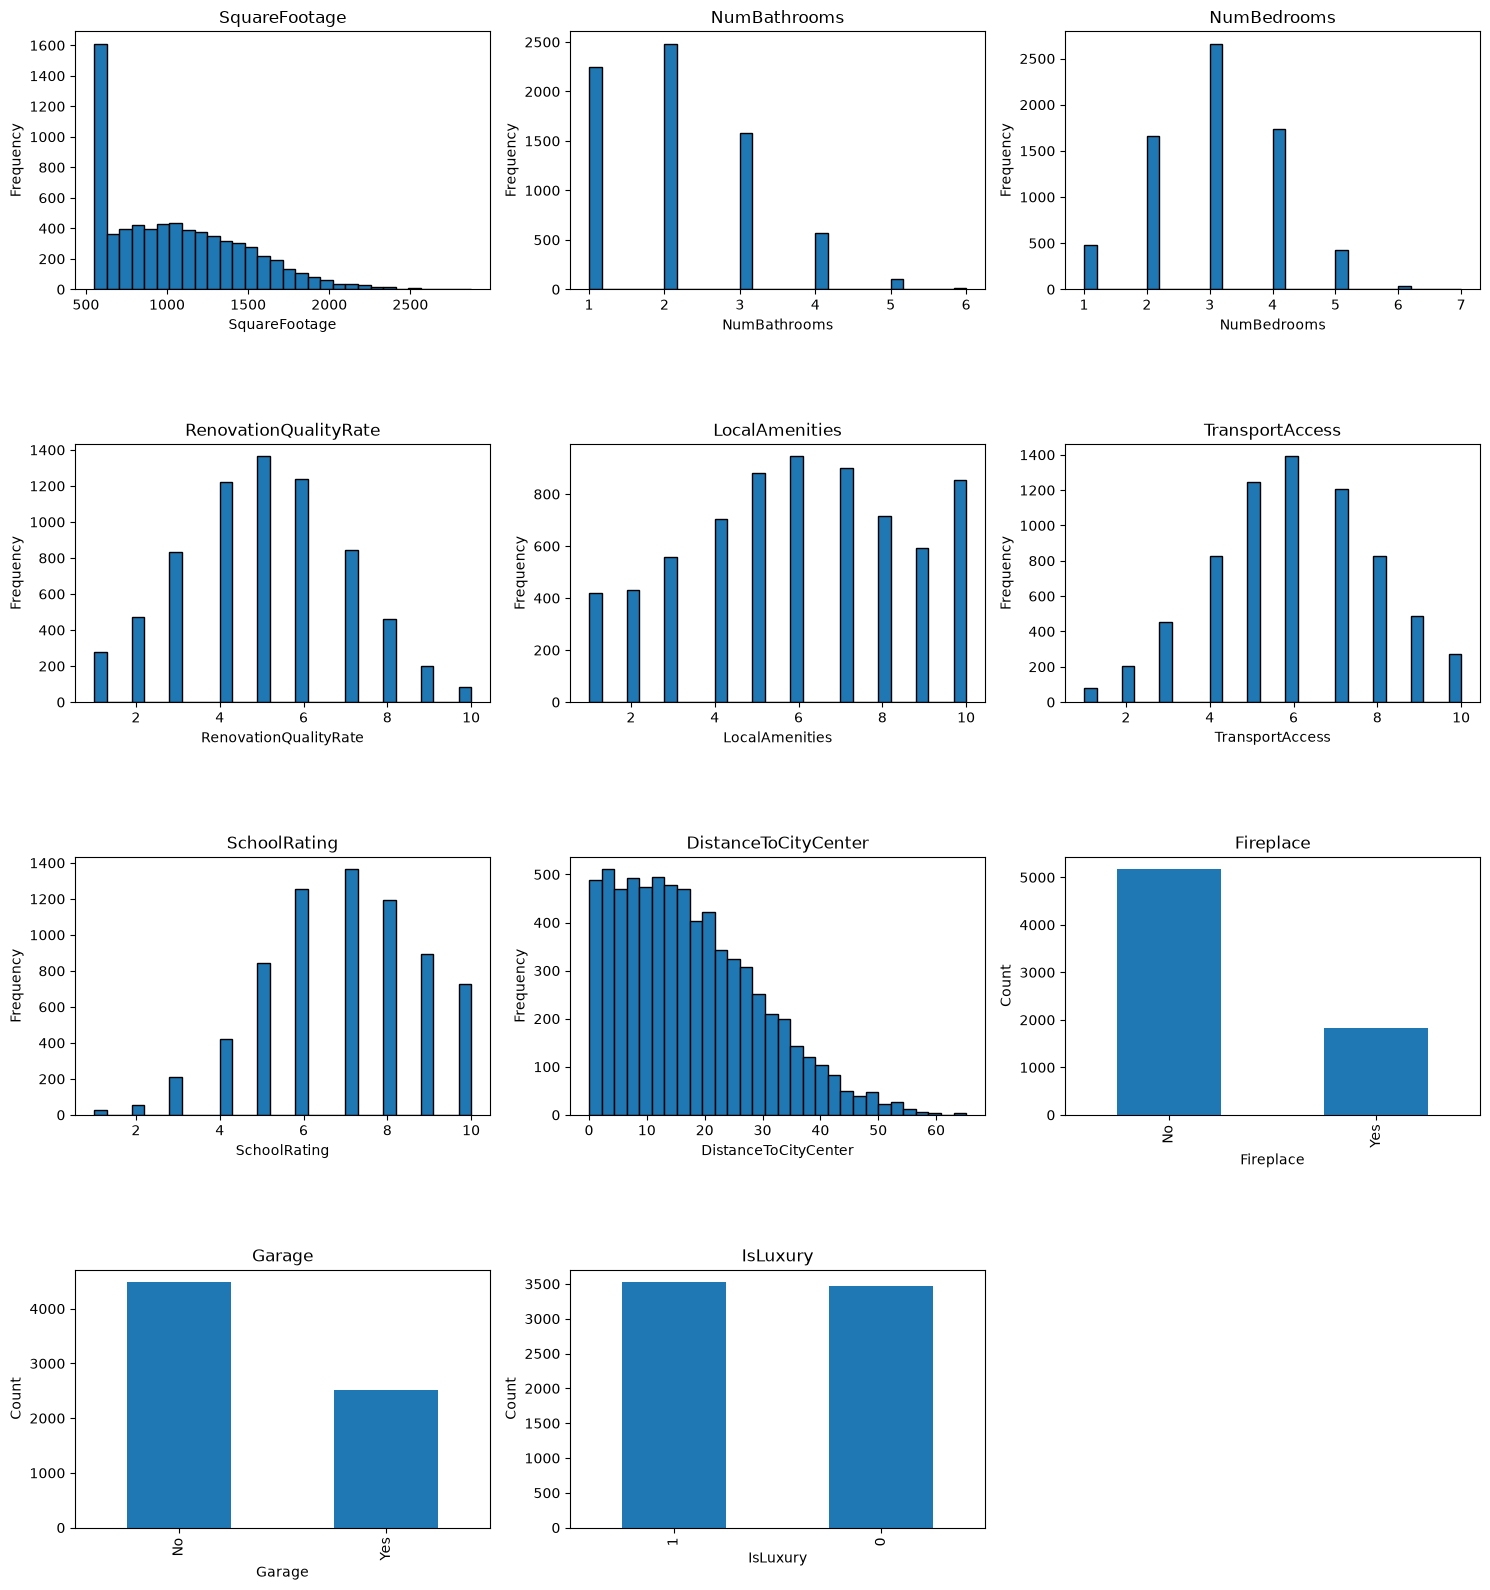

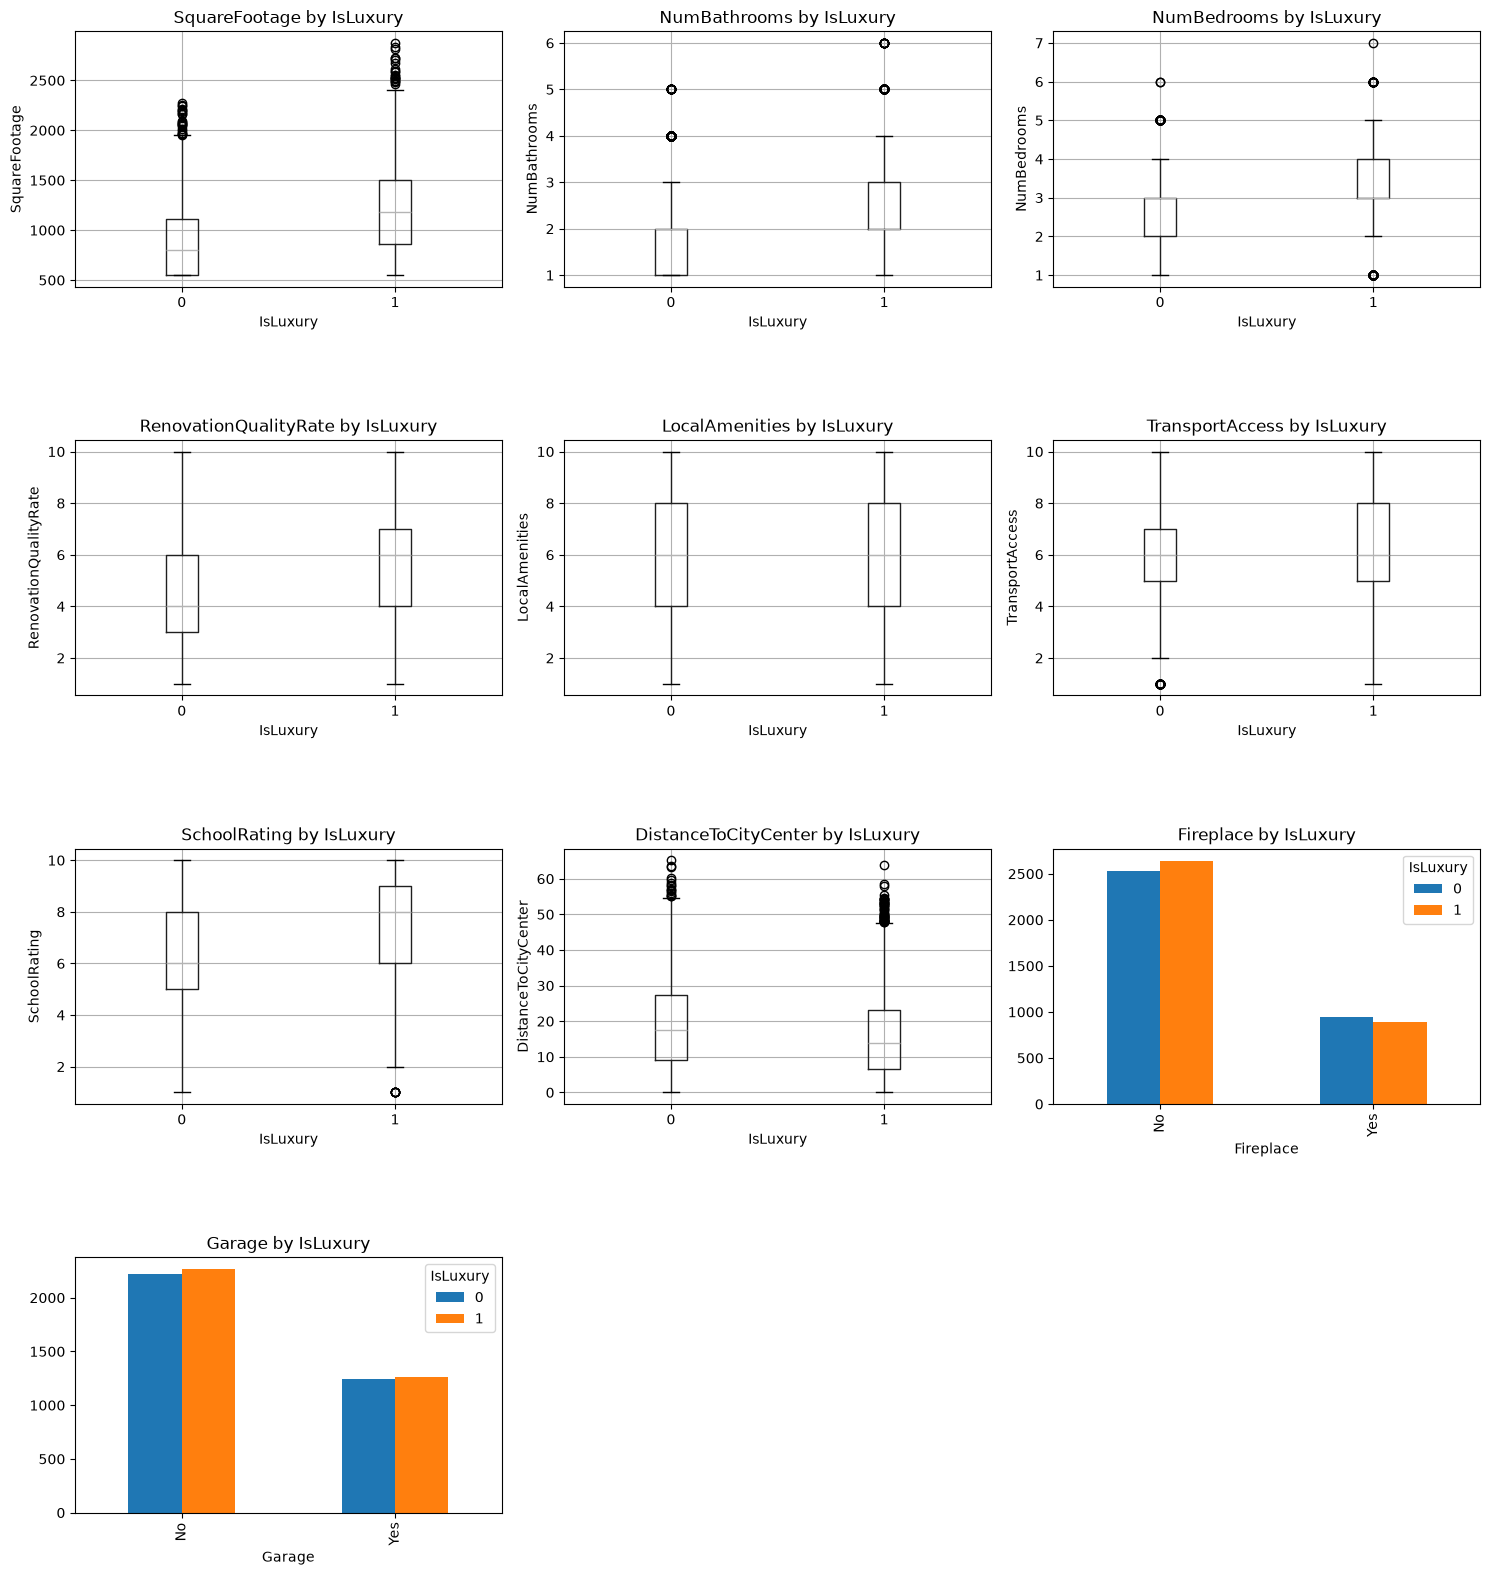

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score


df = pd.read_csv('Housing Data.csv')

#--------------DESCRIPTIVE STATISTICS OUTPUT -----------------------------------

columns = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
           'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter']

stats = df[columns].describe()
stats.loc['range'] = df[columns].max() - df[columns].min()
stats.loc['variance'] = df[columns].var()

print(stats)
print("\nFrequency counts and percentages for categorical variables:\n")

#Fireplace categorical frequency counts and percentages
print(df['Fireplace'].value_counts())
print()
print(df['Fireplace'].value_counts(normalize=True) * 100)
print()

#Garage categorical  frequency counts and percentages
print(df['Garage'].value_counts())
print()
print(df['Garage'].value_counts(normalize=True) * 100)
print()

#IsLuxury  frequency counts and percentages
print(df['IsLuxury'].value_counts())
print()
print(df['IsLuxury'].value_counts(normalize=True) * 100)

#--------------------------------------UNIVARIATE VISUALIZATIONS -------------------------------------------

quantitative_columns = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
                         'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter']

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, col in enumerate(quantitative_columns):
    axes[i].hist(df[col], bins=30, edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

#Fireplace bar chart
df['Fireplace'].value_counts().plot(kind='bar', ax=axes[len(quantitative_columns)])
axes[len(quantitative_columns)].set_title('Fireplace')
axes[len(quantitative_columns)].set_xlabel('Fireplace')
axes[len(quantitative_columns)].set_ylabel('Count')

#Garage bar chart
df['Garage'].value_counts().plot(kind='bar', ax=axes[len(quantitative_columns)+1])
axes[len(quantitative_columns)+1].set_title('Garage')
axes[len(quantitative_columns)+1].set_xlabel('Garage')
axes[len(quantitative_columns)+1].set_ylabel('Count')

#IsLuxury (DV) bar chart
df['IsLuxury'].value_counts().plot(kind='bar', ax=axes[len(quantitative_columns)+2])
axes[len(quantitative_columns)+2].set_title('IsLuxury')
axes[len(quantitative_columns)+2].set_xlabel('IsLuxury')
axes[len(quantitative_columns)+2].set_ylabel('Count')

#hides empty grid
for j in range(len(quantitative_columns)+3, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.subplots_adjust(hspace=0.6)
plt.savefig('univariate_visualizations.png', dpi=500)

#--------------------BIVARIATE VISUALIZATIONS -----------------------

selected_iv = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
               'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter']

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, col in enumerate(selected_iv):
    df.boxplot(column=col, by='IsLuxury', ax=axes[i])
    axes[i].set_title(f'{col} by IsLuxury')
    axes[i].set_xlabel('IsLuxury')
    axes[i].set_ylabel(col)

#Fireplace vs IsLuxury - crosstab bar chart
pd.crosstab(df['Fireplace'], df['IsLuxury']).plot(kind='bar', ax=axes[len(selected_iv)])
axes[len(selected_iv)].set_title('Fireplace by IsLuxury')

#Garage vs IsLuxury - crosstab bar chart
pd.crosstab(df['Garage'], df['IsLuxury']).plot(kind='bar', ax=axes[len(selected_iv)+1])
axes[len(selected_iv)+1].set_title('Garage by IsLuxury')

#hides 12th empty grid
for j in range(len(selected_iv)+2, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('')
plt.tight_layout()
plt.subplots_adjust(hspace=0.6)
plt.savefig('bivariate_visualizations.png', dpi=500)


#-------DATA CLEANING-----------------------------------------------
print()
print('CLEANING... DETECTION')

#data cleaning methods referenced from the Pandas Cheat Sheet

#check for duplicate rows in the dataset
duplicate_count = df.duplicated().sum()
print("\ntotal duplicate rows found:", duplicate_count)

#check each column for missing entries
print("\nnull value count by column:")
print(df.isnull().sum())

#check selected columns for negative/illogical values
columns = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
           'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter']

print("\nnegative value count:")
for col in columns:
    print(f"{col}: {(df[col] < 0).sum()} negative values")

#check categorical column(s) for inconsistent label formatting
categorical_columns = ['Fireplace', 'Garage']

print("\nUnique category values by column:")
for col in categorical_columns:
    print(f" {col} ")
    print(df[col].unique())

#check IsLuxury for unique values
print("\nIsLuxury unique values:")
print(df['IsLuxury'].unique())

#check column names for formatting issues
print("\nColumn names:", list(df.columns))

#check data types for each column
print("\nData type variations:")
print(df.dtypes)

#outlier detection using IQR method
numeric_columns = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
                    'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter']

for col in numeric_columns:    
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_boundary = Q1 - 1.5 * IQR
    upper_boundary = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_boundary) | (df[col] > upper_boundary)]
    print(f"{col}: {len(outliers)} outliers (bounds: {lower_boundary:.2f} to {upper_boundary:.2f})")

#encoding Fireplace and Garage
df['Fireplace'] = df['Fireplace'].map({'Yes': 1, 'No': 0})
df['Garage'] = df['Garage'].map({'Yes': 1, 'No': 0})


#mitigate outliers by capping IQR 
cols_to_cap = ['SquareFootage', 'DistanceToCityCenter']

for col in cols_to_cap:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bounds = Q1 - 1.5 * IQR
    upper_bounds = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower=lower_bounds, upper=upper_bounds)

cleaned_columns = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
                    'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter', 
                    'Fireplace', 'Garage', 'IsLuxury']

df[cleaned_columns].to_csv('cleaned_dataset.csv', index=False)

#-----------------------------------SPLIT---------------------------

#define variables
independent = df[['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 
                   'LocalAmenities', 'TransportAccess', 'SchoolRating', 'DistanceToCityCenter',
                   'Fireplace', 'Garage']]
dependent = df['IsLuxury']

#70/30 train/test split
independent_train, independent_test, dependent_train, dependent_test = train_test_split(
    independent, dependent, test_size=0.3, random_state=100
)

print()
print("Training shape:", independent_train.shape)
print("Testing shape:", independent_test.shape)

#exports training dataset
train_export = independent_train.copy()
train_export['IsLuxury'] = dependent_train
train_export.to_csv('training_dataset.csv', index=False)

#exports testing dataset
test_export = independent_test.copy()
test_export['IsLuxury'] = dependent_test
test_export.to_csv('testing_dataset.csv', index=False)

#----------------STATISTICAL METHOD ---------------------
print()

#adds intercept to the independent variables
independent_train_constant = sm.add_constant(independent_train)

#build the logistic regression model 
model = sm.Logit(dependent_train, independent_train_constant).fit()

#model summary
print(model.summary())
print("AIC:", model.aic)
print("BIC:", model.bic)

print('\nOptimization Starting Point\n')

#--------------------BACKWARD STEPWISE ELIMINATION ---------

#step 1: remove Garage 
independent_train_opt = independent_train.drop(columns=['Garage'])
independent_train_opt_constant = sm.add_constant(independent_train_opt)
model_opt = sm.Logit(dependent_train, independent_train_opt_constant).fit()

#step 2: remove Fireplace
independent_train_opt = independent_train_opt.drop(columns=['Fireplace'])
independent_train_opt_constant = sm.add_constant(independent_train_opt)
model_opt = sm.Logit(dependent_train, independent_train_opt_constant).fit()

#step 3: remove SchoolRating
independent_train_opt = independent_train_opt.drop(columns=['SchoolRating'])
independent_train_opt_constant = sm.add_constant(independent_train_opt)
model_opt = sm.Logit(dependent_train, independent_train_opt_constant).fit()

#step 4: remove DistanceToCityCenter
independent_train_opt = independent_train_opt.drop(columns=['DistanceToCityCenter'])
independent_train_opt_constant = sm.add_constant(independent_train_opt)
model_opt = sm.Logit(dependent_train, independent_train_opt_constant).fit()

#step 5: remove TransportAccess
independent_train_opt = independent_train_opt.drop(columns=['TransportAccess'])
independent_train_opt_constant = sm.add_constant(independent_train_opt)
model_opt = sm.Logit(dependent_train, independent_train_opt_constant).fit()

print("\nOptimization Complete:\n")
print(model_opt.summary())
print("AIC:", model_opt.aic)
print("BIC:", model_opt.bic)

#----=--------------PREDICTION WITH TEST SET -----------------------------
print()
#5 variables 
final_variables = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 'LocalAmenities']

independent_test_final = independent_test[final_variables]
independent_test_final_constant = sm.add_constant(independent_test_final)

#probability of IsLuxury prediction
predicted_probabilities = model_opt.predict(independent_test_final_constant)

#0.5 threshold for probabilities 
predicted_classes = (predicted_probabilities >= 0.5).astype(int)

#confusion matrix
conf_matrix = confusion_matrix(dependent_test, predicted_classes)
print("Confusion Matrix:")
print(conf_matrix)
print()

#accuracy check
accuracy = accuracy_score(dependent_test, predicted_classes)
print("\nAccuracy:", accuracy)

#------------ASSUMPTIONS ---------------------------------------------
print("\nAssumptions:\n")

vif_data = pd.DataFrame()
vif_data['Variable'] = independent_train_opt.columns
vif_data['VIF'] = [variance_inflation_factor(independent_train_opt.values, i) for i in range(independent_train_opt.shape[1])]

print(vif_data)
print()

#linearity using Box-Tidwell
continuous_variables = ['SquareFootage', 'NumBathrooms', 'NumBedrooms', 'RenovationQualityRate', 'LocalAmenities']

box_tidwell_df = independent_train_opt.copy()

for var in continuous_variables:
    box_tidwell_df[f'{var}_log_interaction'] = box_tidwell_df[var] * np.log(box_tidwell_df[var])

box_tidwell_constant = sm.add_constant(box_tidwell_df)
box_tidwell_model = sm.Logit(dependent_train, box_tidwell_constant).fit()
print(box_tidwell_model.summary())